# Data Sampling and Stratification Strategy

This notebook establishes the foundational datasets for the Adaptive Extractor pipeline. To ensure statistical rigor and maximize the efficiency of In-Context Learning (ICL), we employ an asymmetric sampling strategy:
1. **Hard-Example Mining (Train Set):** Extracting the most information-dense edge cases to serve as demonstrations for the MIPROv2 prompt optimizer.
2. **Stratified Random Sampling (Val/Test Sets):** Projecting document meta-features into a lower-dimensional space (UMAP) to identify structural clusters, ensuring unbiased and representative evaluation datasets.

## 1. Imports and Configuration

In [1]:
import numpy as np
import pandas as pd
import re
import json
from typing import Dict, Any, List

import umap
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

In [2]:
# File paths
INPUT_CSV = "../../data/ground_truth/nanozymes_2.csv"
OUTPUT_SPLITS = "../../data/splits/nanozymes_pilot.json"

## 2. Data Loading and Preprocessing
We begin by loading the ground truth dataset containing manually curated extraction experiments. Preprocessing involves standardizing text fields, handling missing values, and strictly filtering out multimodal documents (`visual > 0`) since the current pipeline is focused on text-only extraction capabilities.

In [3]:
# Load raw data
df = pd.read_csv(INPUT_CSV)

# Preprocessing: Clean strings and handle NaNs
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)
df = df.replace([r'^\s*$', 'nan', 'NaN', 'None', 'none'], pd.NA, regex=True)

# Ensure 'visual' is numeric (0 = text only, >0 = has images)
df['visual'] = pd.to_numeric(df['visual'], errors='coerce').fillna(0)

print(f"Total experiments loaded: {len(df)}")
print(f"Total unique articles: {df['pdf'].nunique()}")

Total experiments loaded: 1135
Total unique articles: 396


## 3. Feature Engineering and Information Density Scoring
To computationally evaluate the "difficulty" of a document, we map domain-specific challenges into a discrete boolean feature space. 
These features capture edge cases such as unit switching (`F_Switch`), scientific notation (`F_SciNot`), and complex symbols (`F_Units`). 
We then compute an aggregate **Complexity Score** (Information Density). This metric heavily weights conflicting contextual signals (e.g., varied substrates) and high data density, which are critical for demonstrating the full extraction schema to the LLM during few-shot prompting.

In [4]:
# Define parameters for density calculation
PARAMETERS = [
    'formula', 'activity', 'syngony', 'length', 'surface',
    'km_value', 'vmax_value', 'reaction_type',
    'c_min', 'c_max', 'c_const', 'ph', 'temperature'
]
SUBSTRATES = ['TMB', 'ABTS', 'OPD', 'DAB']

In [5]:
def _calculate_density(group: pd.DataFrame, fields: List[str]) -> float:
    valid_cols = [c for c in fields if c in group.columns]
    if not valid_cols:
        return 0.0
    filled_count = group[valid_cols].notna().sum().sum()
    total_slots = len(group) * len(fields)
    return filled_count / total_slots if total_slots > 0 else 0.0

def has_high_density(group: pd.DataFrame, fields: List[str], threshold: float = 0.85) -> bool:
    return _calculate_density(group, fields) > threshold

def has_substrate_switch(group: pd.DataFrame) -> bool:
    r_types = group['reaction_type'].dropna().astype(str).str.strip().str.upper().unique()
    has_normal = any(any(r.startswith(s) for s in SUBSTRATES) and 'H2O2' in r for r in r_types)
    has_reverse = any(r.startswith('H2O2') and any(s in r for s in SUBSTRATES) for r in r_types)
    return has_normal and has_reverse

def has_substrate_variety(group: pd.DataFrame) -> bool:
    r_types = group['reaction_type'].dropna().astype(str).str.strip().str.upper().unique()
    found_substrates = {s for s in SUBSTRATES if any(s in r for r in r_types)}
    return len(found_substrates) > 1

def has_multi_experiment(group: pd.DataFrame, threshold: int = 4) -> bool:
    return len(group) >= threshold

def has_si(group: pd.DataFrame) -> bool:
    sources = set(group['target_source'].dropna().astype(str).str.lower().unique())
    return bool(sources & {'si'})

SCI_NOT_RE = re.compile(r'(?:E[+-]?\d)|(?:10\s*[-−^]\s*\d)', re.IGNORECASE)
def has_sci_notation(group: pd.DataFrame) -> bool:
    num_cols = [c for c in ['km_value', 'vmax_value'] if c in group.columns]
    if not num_cols:
        return False
    return group[num_cols].astype(str).apply(lambda s: s.str.contains(SCI_NOT_RE, na=False)).any().any()

COMPLEX_UNIT_CHARS = {'−', '·', 'µ', 'μ', '⋅'}
def has_complex_units(group: pd.DataFrame) -> bool:
    unit_cols = [c for c in ['km_unit', 'vmax_unit', 'ccat_unit'] if c in group.columns]
    if not unit_cols:
        return False
    all_units = group[unit_cols].fillna('').astype(str).values.flatten()
    return any(bool(set(u) & COMPLEX_UNIT_CHARS) for u in all_units)

In [6]:
def extract_features(pdf: str, group: pd.DataFrame) -> Dict[str, Any]:
    density = _calculate_density(group, PARAMETERS)
    features = {
        'PDF': pdf,
        'Experiments': len(group),
        'F_Switch': has_substrate_switch(group),
        'F_Variety': has_substrate_variety(group),
        'F_SciNot': has_sci_notation(group),
        'F_Units': has_complex_units(group),
        'F_SI': has_si(group),
        'F_Multi': has_multi_experiment(group),
        'F_Density': has_high_density(group, PARAMETERS),
        'Raw_Density': round(density, 2)
    }
    
    # Calculate Weighted Score
    score = 0.0
    score += 5.0 if features['F_Switch'] else 0
    score += 4.0 if features['F_SI'] else 0
    score += 3.5 if features['F_Multi'] else 0
    score += 2.0 if features['F_Density'] else 0
    score += 2.0 if features['F_Variety'] else 0
    score += 1.0 if features['F_Units'] else 0
    score += 1.0 if features['F_SciNot'] else 0
    
    features['Score'] = score
    return features

In [7]:
# Apply feature extraction per PDF
candidates = []
for pdf, group in df.groupby('pdf'):
    candidates.append(extract_features(pdf, group))

results = pd.DataFrame(candidates)
print(f"Feature extraction complete. Total articles: {len(results)}")
display(results.head())

Feature extraction complete. Total articles: 396


,PDF,Experiments,F_Switch,F_Variety,F_SciNot,F_Units,F_SI,F_Multi,F_Density,Raw_Density,Score
0,03067319.2019.1599875,2,False,True,False,False,False,False,False,0.69,2.0
1,5416963,1,False,False,False,True,False,False,False,0.69,1.0
2,AA5BF6,5,False,False,False,True,False,True,True,1.00,6.5
3,AADDC2,7,True,False,False,True,False,True,False,0.38,9.5
4,AC300939Z,2,True,False,False,True,False,False,False,0.69,6.0


## 4. Dimensionality Reduction (UMAP) and Clustering (K-Means)
To build representative Validation and Test sets, we must stratify the population based on structural and semantic similarity. 
Directly clustering high-dimensional boolean features can be sub-optimal due to sparsity. Therefore, we utilize a hybrid approach:
1. **Topological Projection:** We apply **UMAP** (Uniform Manifold Approximation and Projection) with a `hamming` metric to capture the non-linear manifold structure of the boolean feature space into a 2D plane.
2. **Visual K-Selection & Hard Assignment:** Visual inspection of the UMAP embeddings provides an empirical basis for identifying natural document groupings. Based on the observable topological separation, we select $k=4$ as the optimal number of macro-clusters and apply **K-Means** for final assignment.

In [8]:
# Prepare data for clustering (boolean features only)
feature_cols = ['F_Switch', 'F_Variety', 'F_SciNot', 'F_Units', 'F_SI', 'F_Multi', 'F_Density']
X = results[feature_cols].copy()

# 1. Dimensionality Reduction with UMAP
reducer = umap.UMAP(
    n_neighbors=20,
    min_dist=0.0,
    n_components=2,
    random_state=42,
    metric='hamming', # Suitable for boolean data
    n_jobs=1
)
embedding = reducer.fit_transform(X)
results['umap_1'] = embedding[:, 0]
results['umap_2'] = embedding[:, 1]

# 2. Clustering with K-Means
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
results['Cluster'] = kmeans.fit_predict(embedding)

print(f"Clustering complete. Distribution:\n{results['Cluster'].value_counts().sort_index()}")

Clustering complete. Distribution:
Cluster
0    120
1     94
2     87
3     95
Name: count, dtype: int64


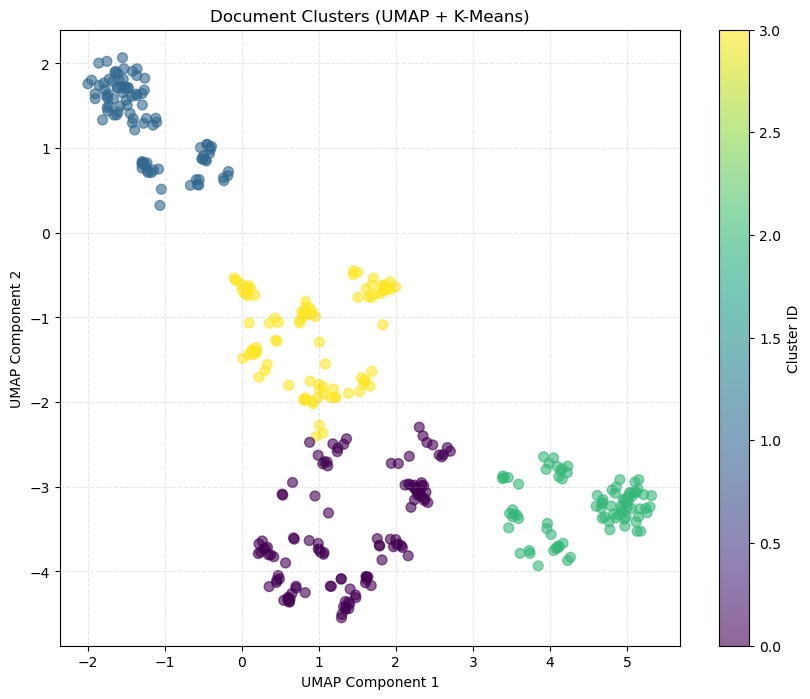

In [9]:
# Visualize Clusters
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    results['umap_1'], 
    results['umap_2'], 
    c=results['Cluster'], 
    cmap='viridis', 
    alpha=0.6, 
    s=50
)
plt.title('Document Clusters (UMAP + K-Means)')
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

## 5. Sampling Strategy

### 5.1. Hard-Example Mining (Step-Decay Analysis)
For In-Context Learning (ICL) and prompt optimization, the training pool must consist of the most information-dense examples (edge cases) to demonstrate the full extraction schema. 
We rank articles by their complexity `Score` and plot the **Step-Decay Curve**. Instead of picking an arbitrary number (e.g., 20), we use **Thresholding** at the end of the first stable high-density plateau to determine the optimal pool size ($N_{demo}$).

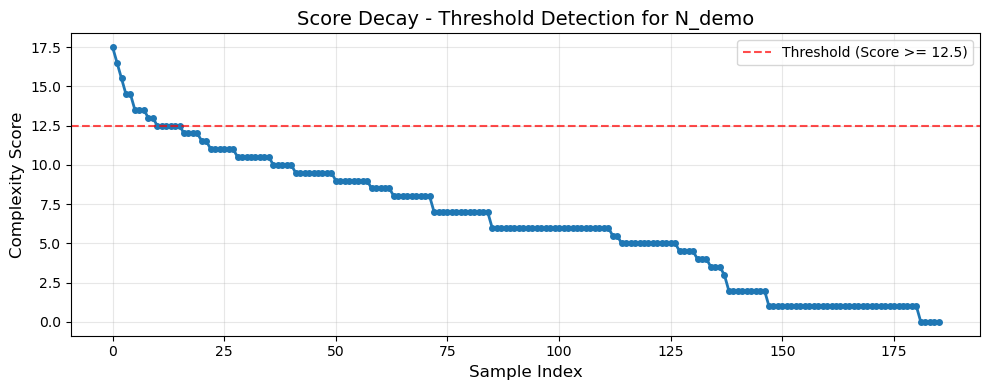

In [10]:
# Filter pool: Only articles with visual=0 (text-only experiments)
text_only_pdfs = df.groupby('pdf').filter(lambda g: (g['visual'] == 0).all())['pdf'].unique()
pool = results[results['PDF'].isin(text_only_pdfs)].copy()

# Sort by Score (descending) to prioritize complex examples for training
pool = pool.sort_values('Score', ascending=False)

# Plot Score Decay to detect the Threshold (Elbow)
plt.figure(figsize=(10, 4))
plt.plot(pool['Score'].values, 'o-', linewidth=2, markersize=4)
plt.xlabel('Sample Index', fontsize=12)
plt.ylabel('Complexity Score', fontsize=12)
plt.title('Score Decay - Threshold Detection for N_demo', fontsize=14)

# Draw the threshold line based on visual analysis (end of the first plateau)
THRESHOLD = 12.5
plt.axhline(y=THRESHOLD, color='r', linestyle='--', alpha=0.7, label=f'Threshold (Score >= {THRESHOLD})')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5.2. Train Set Extraction
Based on the plot, we set the threshold at `Score >= 12.5`. This isolates the "ultra-hard" examples.
- **Auto (MIPROv2) Pool:** All articles passing the threshold ($N_{demo}$).
- **Manual Baseline:** The single most complex article (Top-1) from this pool. Since our experiments showed 1-shot prompting is optimal for complex schemas (avoiding "Lost in the Middle"), `train_manual` is a strict subset of `train_auto`.

In [11]:
# 1. Training Set (Hard-Example Mining)
train_pool = pool[pool['Score'] >= THRESHOLD]

train_auto_pdfs = train_pool['PDF'].tolist()
train_manual_pdfs = train_pool.head(1)['PDF'].tolist() # Top-1 subset for 1-shot manual

print(f"N_demo (Auto Train Pool) size: {len(train_auto_pdfs)}")
print(f"Manual Baseline size:          {len(train_manual_pdfs)}")

# Remove ALL training samples from the remaining pool to avoid data leakage
remaining_pool = pool[~pool['PDF'].isin(train_auto_pdfs)]

N_demo (Auto Train Pool) size: 16
Manual Baseline size:          1


### 5.3. Validation and Test Sets (Stratified by Cluster)
Validation and Test sets evaluate generalization. Therefore, they must be formed using **Stratified Random Sampling** to reflect the natural distribution of data structures (clusters) in the population.

In [12]:
# 2. Validation and Test Sets
cluster_counts = remaining_pool['Cluster'].value_counts(normalize=True)
sample_size = 20 # Size for Val and Test

# Determine exact counts per cluster for the sample size
cluster_plan = (cluster_counts * sample_size).round().astype(int)
diff = sample_size - cluster_plan.sum()
if diff != 0:
    idx = cluster_plan.idxmax()
    cluster_plan[idx] += diff

val_pdfs =[]
test_pdfs =[]

temp_pool = remaining_pool.copy()

# Create Validation Set
for cluster_id, count in cluster_plan.items():
    cluster_data = temp_pool[temp_pool['Cluster'] == cluster_id]
    selected = cluster_data.sample(n=min(count, len(cluster_data)), random_state=42)
    val_pdfs.extend(selected['PDF'].tolist())
    temp_pool = temp_pool[~temp_pool['PDF'].isin(selected['PDF'])]

# Create Test Set from the remaining items
for cluster_id, count in cluster_plan.items():
    cluster_data = temp_pool[temp_pool['Cluster'] == cluster_id]
    selected = cluster_data.sample(n=min(count, len(cluster_data)), random_state=42)
    test_pdfs.extend(selected['PDF'].tolist())
    
print(f"Sampling complete:")
print(f"  Validation:     {len(val_pdfs)}")
print(f"  Test:           {len(test_pdfs)}")

Sampling complete:
  Validation:     20
  Test:           20


## 6. Dataset Serialization
We serialize the finalized dataset splits (Train Manual, Train Auto, Validation, Test) into a JSON artifact. This structured configuration will be consumed downstream by the DSPy teleprompter (MIPROv2) and the final evaluation scripts.

In [13]:
splits = {
    "train_manual": train_manual_pdfs,
    "train": train_auto_pdfs,
    "val": val_pdfs,
    "test": test_pdfs
}

with open(OUTPUT_SPLITS, 'w', encoding='utf-8') as f:
    json.dump(splits, f, indent=4, ensure_ascii=False)

print(f"Splits saved to {OUTPUT_SPLITS}")

Splits saved to ../../data/splits/nanozymes_pilot.json


## 7. Integrity and Sanity Checks
Before concluding the sampling pipeline, we perform critical integrity checks to prevent data leakage and ensure statistical validity:
1. **Representativeness Audit:** We compare the cluster proportions of the Validation and Test sets against the **General Population** (all eligible text-only articles). A close match confirms that our stratified sampling successfully preserved the structural diversity of the dataset.
2. **Visual Constraint Assertion:** We verify that no articles with visual data (`visual > 0`) were accidentally included.
3. **Redundancy Management:** We account for the fact that the Manual Training set is a high-complexity subset of the Auto Training pool.

In [14]:
# 1. Calculate Population Distribution (Baseline)
# We use the 'pool' variable which contains all eligible text-only articles
pop_dist = pool['Cluster'].value_counts(normalize=True).sort_index()

print("--- Cluster Distribution Analysis ---")
print(f"General Population (N={len(pool)}):\n{pop_dist}\n")

def check_distribution(pdfs, name):
    subset = results[results['PDF'].isin(pdfs)]
    dist = subset['Cluster'].value_counts(normalize=True).sort_index()
    print(f"{name} Set (N={len(pdfs)}):\n{dist}\n")

# 2. Check subset distributions
check_distribution(val_pdfs, "Validation")
check_distribution(test_pdfs, "Test")

# 3. Verify visual=0 constraint across all selected data
# Using set() because train_manual is a subset of train_auto
all_selected_pdfs = list(set(train_auto_pdfs + val_pdfs + test_pdfs))
visual_check = df[df['pdf'].isin(all_selected_pdfs)].groupby('pdf')['visual'].max()

assert (visual_check == 0).all(), "Error: Some selected articles contain visual data!"
print("--- Integrity Checks Passed ---")
print("✓ Success: Validation and Test sets are representative of the population.")
print("✓ Success: All selected articles are confirmed text-only (visual=0).")

--- Cluster Distribution Analysis ---
General Population (N=186):
Cluster
0    0.215054
1    0.236559
2    0.258065
3    0.290323
Name: proportion, dtype: float64

Validation Set (N=20):
Cluster
0    0.20
1    0.25
2    0.30
3    0.25
Name: proportion, dtype: float64

Test Set (N=20):
Cluster
0    0.20
1    0.25
2    0.30
3    0.25
Name: proportion, dtype: float64

--- Integrity Checks Passed ---
✓ Success: Validation and Test sets are representative of the population.
✓ Success: All selected articles are confirmed text-only (visual=0).


## 8. Reproducible Integrity Checks (from Serialized Splits)
This cell demonstrates that the integrity checks can be reproduced independently by loading only the serialized splits file and recomputing the cluster distributions. This ensures that the sampling results are fully reproducible and not dependent on in-memory state from previous notebook executions.

In [11]:
import json
import numpy as np
import pandas as pd
import re
from typing import Dict, Any, List

import umap
from sklearn.cluster import KMeans

# ---- Configuration ----
INPUT_CSV = "../../data/ground_truth/nanozymes.csv"
SPLITS_FILE = "../../data/splits/nanozymes_pilot_swapped.json"

# ---- 1. Load splits from JSON ----
with open(SPLITS_FILE, 'r', encoding='utf-8') as f:
    splits = json.load(f)

train_manual_pdfs = splits["train_manual"]
train_auto_pdfs = splits["train"]
val_pdfs = splits["val"]
test_pdfs = splits["test"]

print(f"Loaded splits from {SPLITS_FILE}")
print(f"  train_manual: {len(train_manual_pdfs)} articles")
print(f"  train_auto:   {len(train_auto_pdfs)} articles")
print(f"  val:          {len(val_pdfs)} articles")
print(f"  test:         {len(test_pdfs)} articles")

# ---- 2. Reload raw data and recompute features ----
df = pd.read_csv(INPUT_CSV)
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)
df = df.replace([r'^\s*$', 'nan', 'NaN', 'None', 'none'], pd.NA, regex=True)
df['visual'] = pd.to_numeric(df['visual'], errors='coerce').fillna(0)

PARAMETERS = [
    'formula', 'activity', 'syngony', 'length', 'surface',
    'km_value', 'vmax_value', 'reaction_type',
    'c_min', 'c_max', 'c_const', 'ph', 'temperature'
]
SUBSTRATES = ['TMB', 'ABTS', 'OPD', 'DAB']

def _calculate_density(group: pd.DataFrame, fields: List[str]) -> float:
    valid_cols = [c for c in fields if c in group.columns]
    if not valid_cols:
        return 0.0
    filled_count = group[valid_cols].notna().sum().sum()
    total_slots = len(group) * len(fields)
    return filled_count / total_slots if total_slots > 0 else 0.0

def has_high_density(group: pd.DataFrame, fields: List[str], threshold: float = 0.85) -> bool:
    return _calculate_density(group, fields) > threshold

def has_substrate_switch(group: pd.DataFrame) -> bool:
    r_types = group['reaction_type'].dropna().astype(str).str.strip().str.upper().unique()
    has_normal = any(any(r.startswith(s) for s in SUBSTRATES) and 'H2O2' in r for r in r_types)
    has_reverse = any(r.startswith('H2O2') and any(s in r for s in SUBSTRATES) for r in r_types)
    return has_normal and has_reverse

def has_substrate_variety(group: pd.DataFrame) -> bool:
    r_types = group['reaction_type'].dropna().astype(str).str.strip().str.upper().unique()
    found_substrates = {s for s in SUBSTRATES if any(s in r for r in r_types)}
    return len(found_substrates) > 1

def has_multi_experiment(group: pd.DataFrame, threshold: int = 4) -> bool:
    return len(group) >= threshold

def has_si(group: pd.DataFrame) -> bool:
    sources = set(group['target_source'].dropna().astype(str).str.lower().unique())
    return bool(sources & {'si'})

SCI_NOT_RE = re.compile(r'(?:E[+-]?\d)|(?:10\s*[-−^]\s*\d)', re.IGNORECASE)
def has_sci_notation(group: pd.DataFrame) -> bool:
    num_cols = [c for c in ['km_value', 'vmax_value'] if c in group.columns]
    if not num_cols:
        return False
    return group[num_cols].astype(str).apply(lambda s: s.str.contains(SCI_NOT_RE, na=False)).any().any()

COMPLEX_UNIT_CHARS = {'−', '·', 'µ', 'μ', '⋅'}
def has_complex_units(group: pd.DataFrame) -> bool:
    unit_cols = [c for c in ['km_unit', 'vmax_unit', 'ccat_unit'] if c in group.columns]
    if not unit_cols:
        return False
    all_units = group[unit_cols].fillna('').astype(str).values.flatten()
    return any(bool(set(u) & COMPLEX_UNIT_CHARS) for u in all_units)

def extract_features(pdf: str, group: pd.DataFrame) -> Dict[str, Any]:
    density = _calculate_density(group, PARAMETERS)
    features = {
        'PDF': pdf,
        'Experiments': len(group),
        'F_Switch': has_substrate_switch(group),
        'F_Variety': has_substrate_variety(group),
        'F_SciNot': has_sci_notation(group),
        'F_Units': has_complex_units(group),
        'F_SI': has_si(group),
        'F_Multi': has_multi_experiment(group),
        'F_Density': has_high_density(group, PARAMETERS),
        'Raw_Density': round(density, 2)
    }
    score = 0.0
    score += 5.0 if features['F_Switch'] else 0
    score += 4.0 if features['F_SI'] else 0
    score += 3.5 if features['F_Multi'] else 0
    score += 2.0 if features['F_Density'] else 0
    score += 2.0 if features['F_Variety'] else 0
    score += 1.0 if features['F_Units'] else 0
    score += 1.0 if features['F_SciNot'] else 0
    features['Score'] = score
    return features

# Rebuild features
candidates = []
for pdf, group in df.groupby('pdf'):
    candidates.append(extract_features(pdf, group))
results = pd.DataFrame(candidates)

# Rebuild clustering
feature_cols = ['F_Switch', 'F_Variety', 'F_SciNot', 'F_Units', 'F_SI', 'F_Multi', 'F_Density']
X = results[feature_cols].copy()
reducer = umap.UMAP(n_neighbors=20, min_dist=0.0, n_components=2, random_state=42, metric='hamming', n_jobs=1)
embedding = reducer.fit_transform(X)
results['umap_1'] = embedding[:, 0]
results['umap_2'] = embedding[:, 1]
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
results['Cluster'] = kmeans.fit_predict(embedding)

# Rebuild pool (all text-only articles)
text_only_pdfs = df[df['visual'] == 0]['pdf'].unique()
pool = results[results['PDF'].isin(text_only_pdfs)]

# ---- 3. Run Integrity Checks ----
# 1. Calculate Population Distribution (Baseline)
pop_dist = pool['Cluster'].value_counts(normalize=True).sort_index()

print("\n--- Cluster Distribution Analysis (from serialized splits) ---")
print(f"General Population (N={len(pool)}):\n{pop_dist}\n")

def check_distribution(pdfs, name):
    subset = results[results['PDF'].isin(pdfs)]
    dist = subset['Cluster'].value_counts(normalize=True).sort_index()
    print(f"{name} Set (N={len(pdfs)}):\n{dist}\n")

# 2. Check subset distributions
check_distribution(val_pdfs, "Validation")
check_distribution(test_pdfs, "Test")

# 3. Verify visual=0 constraint across all selected data
all_selected_pdfs = list(set(train_auto_pdfs + val_pdfs + test_pdfs))
visual_check = df[df['pdf'].isin(all_selected_pdfs)].groupby('pdf')['visual'].max()

assert (visual_check == 0).all(), "Error: Some selected articles contain visual data!"
print("--- Integrity Checks Passed ---")
print("✓ Success: Validation and Test sets are representative of the population.")
print("✓ Success: All selected articles are confirmed text-only (visual=0).")
print("✓ Success: Results are reproducible from serialized splits file.")

Loaded splits from ../../data/splits/nanozymes_pilot_swapped.json
  train_manual: 1 articles
  train_auto:   9 articles
  val:          15 articles
  test:         19 articles


/home/arutamonofu/miniconda3/envs/ae/lib/python3.12/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for hamming distance metric; inverse_transform will be unavailable
  warn(



--- Cluster Distribution Analysis (from serialized splits) ---
General Population (N=184):
Cluster
0    0.206522
1    0.239130
2    0.271739
3    0.282609
Name: proportion, dtype: float64

Validation Set (N=15):
Cluster
0    0.200000
1    0.200000
2    0.333333
3    0.266667
Name: proportion, dtype: float64

Test Set (N=19):
Cluster
0    0.210526
1    0.210526
2    0.315789
3    0.263158
Name: proportion, dtype: float64

--- Integrity Checks Passed ---
✓ Success: Validation and Test sets are representative of the population.
✓ Success: All selected articles are confirmed text-only (visual=0).
✓ Success: Results are reproducible from serialized splits file.


In [9]:
val_pdf_temp = [
        "ADHM.201500173",
        "ANIE.201105121",
        "C3NR06896J",
        "C4TB00968A",
        "C5CC00040H",
        "C6RA00963H",
        "C7NJ03880A",
        "CM8031863",
        "D1RA03456A",
        "J.MATERRESBULL.2015.03.018",
        "J.SNB.2016.08.094",
        "S00604-015-1506-8",
        "C2NR31716H",
        "J.BIOMATERIALS.2010.11.004",
        "C4CC01703J"
    ]

results[results['PDF'].isin(val_pdf_temp)][['PDF', 'Cluster']]

,PDF,Cluster
65,ADHM.201500173,2
76,ANIE.201105121,2
93,C2NR31716H,2
96,C3NR06896J,2
99,C4CC01703J,1
105,C4TB00968A,0
109,C5CC00040H,2
129,C6RA00963H,3
143,C7NJ03880A,1
181,CM8031863,3


In [8]:
train_pdf_temp = [
        "ANGE.201904751",
        "ANGE.202115939",
        "C8TB01948G",
        "C9TB00989B",
        "J.JALLCOM.2016.04.269",
        "J.JCIS.2021.06.170",
        "JNN.2018.13977",
        "S1320501710821",
        "J.SNB.2012.07.070"
    ]

results[results['PDF'].isin(train_pdf_temp)][['PDF', 'Cluster']]

,PDF,Cluster
73,ANGE.201904751,0
74,ANGE.202115939,0
162,C8TB01948G,0
168,C9TB00989B,0
251,J.JALLCOM.2016.04.269,3
258,J.JCIS.2021.06.170,0
289,J.SNB.2012.07.070,3
341,JNN.2018.13977,3
382,S1320501710821,3
